In [6]:
# data_preprocessing.py
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load your CSV dataset
df = pd.read_csv('hamrobazaar_extracted_products.csv')

print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())


  Category                           Title  Price_NPR  Condition    Brand  \
0   Laptop  Asus TUF Gaming F15 2000GB SSD     115100   Like New     Asus   
1   Mobile        Samsung Galaxy S24 512GB     130700  Excellent  Samsung   
2   Mobile                OnePlus 11 256GB      88300        New  OnePlus   
3   Mobile           Apple iPhone 12 256GB      62100       Good    Apple   
4   Laptop        MSI Katana 15 2000GB SSD      49900       Used      MSI   

                 Model  Storage_GB  Age_years  Location  
0  Asus TUF Gaming F15        2000        1.0   Chitwan  
1           Galaxy S24         512        0.5  Lalitpur  
2           OnePlus 11         256        1.5   Chitwan  
3            iPhone 12         256        1.0   Chitwan  
4        MSI Katana 15        2000        3.0  Lalitpur  
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Category 

In [8]:
import pandas as pd

df = pd.read_csv('hamrobazaar_extracted_products.csv')
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print("\n--- Column dtypes ---")
print(df.dtypes)

print("\n--- Sample values per column ---")
for col in df.columns:
    print(f"\n{col}: {df[col].unique()[:10]}")

print("\n--- Missing values ---")
print(df.isnull().sum())

Shape: (500, 9)

--- Column dtypes ---
Category          str
Title             str
Price_NPR       int64
Condition         str
Brand             str
Model             str
Storage_GB      int64
Age_years     float64
Location          str
dtype: object

--- Sample values per column ---

Category: <StringArray>
['Laptop', 'Mobile']
Length: 2, dtype: str

Title: <StringArray>
['Asus TUF Gaming F15 2000GB SSD',       'Samsung Galaxy S24 512GB',
               'OnePlus 11 256GB',          'Apple iPhone 12 256GB',
       'MSI Katana 15 2000GB SSD',       'Samsung Galaxy A34 512GB',
          'Dell XPS 13 256GB SSD',               'HP 15s 512GB SSD',
                'Xiaomi 13 256GB',       'Samsung Galaxy S22 256GB']
Length: 10, dtype: str

Price_NPR: [115100 130700  88300  62100  49900  25400  80000  53600  64900  79500]

Condition: <StringArray>
['Like New', 'Excellent', 'New', 'Good', 'Used', 'Fair']
Length: 6, dtype: str

Brand: <StringArray>
[     'Asus',   'Samsung',   'OnePlus',     'A

Loaded dataset: 500 rows, 9 columns
Category          str
Title             str
Price_NPR       int64
Condition         str
Brand             str
Model             str
Storage_GB      int64
Age_years     float64
Location          str
dtype: object

Unique Condition values: <StringArray>
['Like New', 'Excellent', 'New', 'Good', 'Used', 'Fair']
Length: 6, dtype: str
Condition is text-based → mapping to numeric scores
Condition_Score sample: Condition_Score
9.0     133
8.0     132
10.0    108
6.0      80
5.0      47
Name: count, dtype: int64

Rows with valid Price_NPR: 500
After price cleaning: 500 rows

Unique Age_years values: [1.  0.5 1.5 3.  0.  2.  4.  2.5]
Age_years range: 0.0 - 4.0

Unique Storage_GB values: [2000  512  256 1000  128   64 1024]

Duplicates removed: 2
Outliers removed: 2 (IQR bounds: -181200 - 321050)
Rows remaining after outlier removal: 496

Final X shape: (496, 8)
Final y shape: (496,)

Any NaN in X? 0
Any NaN in y? 0

After final NaN drop — X: (496, 8), y: (496,

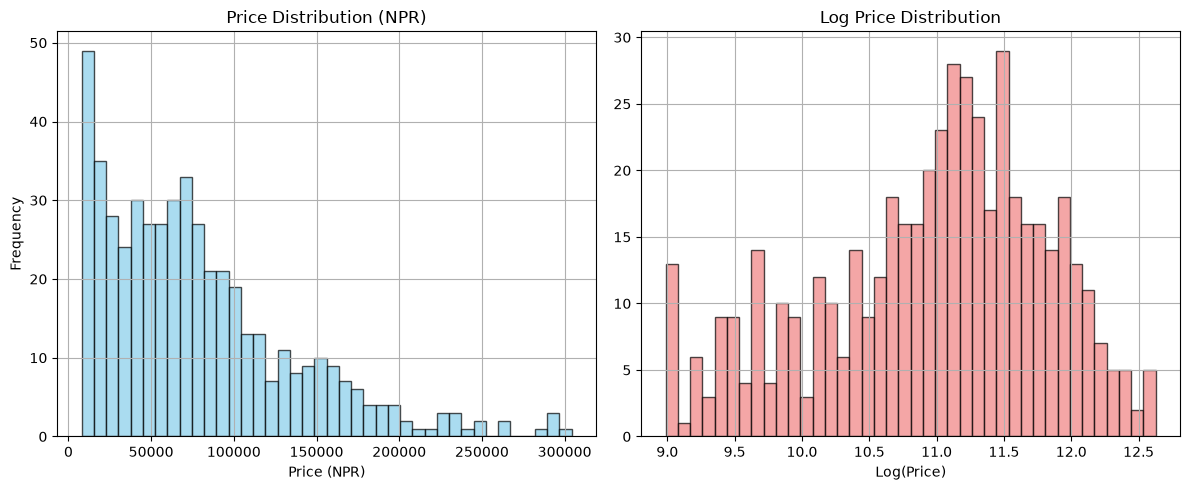

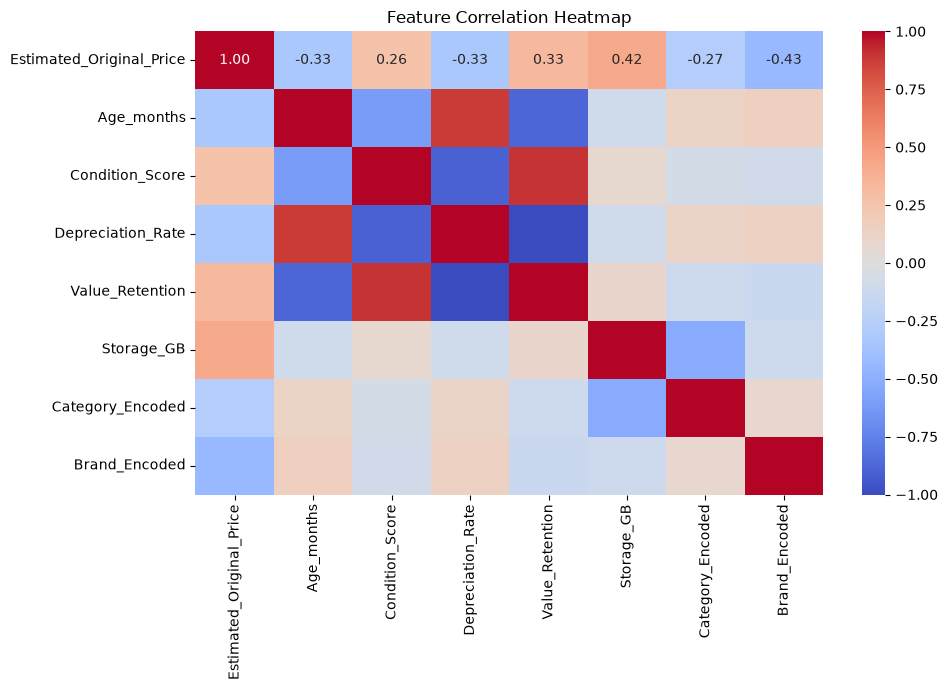


✓ PREPROCESSING COMPLETE
  Rows ready for training: 496
  Features: 8
  Price range: NPR 8000 – 304200


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
import pickle
import os

# ==================== Load Data ====================
df = pd.read_csv('hamrobazaar_extracted_products.csv')
df.columns = df.columns.str.strip()  # Remove hidden spaces

print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print(df.dtypes)

# ==================== Step 1: Handle Condition Column ====================
# Check if Condition is text (e.g. "Good", "Fair") or numeric (1-10)
print("\nUnique Condition values:", df['Condition'].unique())

CONDITION_MAP = {
    # Common text-based condition values → numeric score
    'new':          10,
    'like new':     9,
    'excellent':    8,
    'very good':    7,
    'good':         6,
    'fair':         5,
    'acceptable':   4,
    'poor':         3,
    'bad':          2,
    'broken':       1,
}

# Try converting to numeric first
df['Condition_num'] = pd.to_numeric(df['Condition'], errors='coerce')

# If more than 50% are NaN, it's text-based → map it
if df['Condition_num'].isna().sum() > len(df) * 0.5:
    print("Condition is text-based → mapping to numeric scores")
    df['Condition_Score'] = (
        df['Condition']
        .str.strip()
        .str.lower()
        .map(CONDITION_MAP)
    )
    # For any unmapped values, assign median score
    df['Condition_Score'] = df['Condition_Score'].fillna(5)
else:
    print("Condition is already numeric")
    df['Condition_Score'] = df['Condition_num'].fillna(df['Condition_num'].median())

# Clip to valid range 1-10
df['Condition_Score'] = df['Condition_Score'].clip(1, 10)
print("Condition_Score sample:", df['Condition_Score'].value_counts().head())

# ==================== Step 2: Handle Price Column ====================
df['Price_NPR'] = (
    df['Price_NPR']
    .astype(str)
    .str.replace(',', '')
    .str.replace('NPR', '')
    .str.replace('Rs', '')
    .str.strip()
)
df['Price_NPR'] = pd.to_numeric(df['Price_NPR'], errors='coerce')

print(f"\nRows with valid Price_NPR: {df['Price_NPR'].notna().sum()}")
df = df.dropna(subset=['Price_NPR'])
df = df[df['Price_NPR'] > 0]
print(f"After price cleaning: {len(df)} rows")

# ==================== Step 3: Handle Age Column ====================
print("\nUnique Age_years values:", df['Age_years'].unique()[:10])

df['Age_years'] = (
    df['Age_years']
    .astype(str)
    .str.extract(r'(\d+\.?\d*)')[0]  # Extract first number found
)
df['Age_years'] = pd.to_numeric(df['Age_years'], errors='coerce')
df['Age_years'] = df['Age_years'].fillna(df['Age_years'].median())
df['Age_years'] = df['Age_years'].clip(0, 50)
print(f"Age_years range: {df['Age_years'].min()} - {df['Age_years'].max()}")

# ==================== Step 4: Handle Storage Column ====================
print("\nUnique Storage_GB values:", df['Storage_GB'].unique()[:10])

df['Storage_GB'] = (
    df['Storage_GB']
    .astype(str)
    .str.replace('GB', '')
    .str.replace('TB', '000')
    .str.strip()
)
df['Storage_GB'] = pd.to_numeric(df['Storage_GB'], errors='coerce')
df['Storage_GB'] = df['Storage_GB'].fillna(0)
df['Storage_GB'] = df['Storage_GB'].clip(0, 10000)

# ==================== Step 5: Handle Categorical Columns ====================
df['Brand']    = df['Brand'].fillna('Unknown').astype(str).str.strip()
df['Category'] = df['Category'].fillna('Other').astype(str).str.strip()
df['Location'] = df['Location'].fillna('Kathmandu').astype(str).str.strip()

# ==================== Step 6: Remove Duplicates ====================
before = len(df)
df = df.drop_duplicates(subset=['Title', 'Price_NPR'], keep='first')
print(f"\nDuplicates removed: {before - len(df)}")

# ==================== Step 7: Outlier Removal (Safe) ====================
before = len(df)

# Only remove extreme outliers (use wider bounds: 3*IQR)
Q1 = df['Price_NPR'].quantile(0.25)
Q3 = df['Price_NPR'].quantile(0.75)
IQR = Q3 - Q1

# Guard: if IQR is 0, skip outlier removal
if IQR > 0:
    lower = Q1 - 3 * IQR
    upper = Q3 + 3 * IQR
    df = df[(df['Price_NPR'] >= lower) & (df['Price_NPR'] <= upper)]
    print(f"Outliers removed: {before - len(df)} (IQR bounds: {lower:.0f} - {upper:.0f})")
else:
    print("IQR is 0 — skipping outlier removal to preserve data")

print(f"Rows remaining after outlier removal: {len(df)}")

# ==================== SAFETY CHECK ====================
if len(df) == 0:
    raise ValueError(
        "DataFrame is EMPTY after cleaning! "
        "Check your Condition/Price/Age column values above."
    )

# ==================== Step 8: Feature Engineering ====================
df['Age_months'] = (df['Age_years'] * 12).round().astype(int)

# Estimated original price (using condition + age to estimate depreciation)
age_depreciation   = df['Age_years'] * 0.08           # 8% per year
condition_discount = (10 - df['Condition_Score']) * 0.05  # 5% per condition point lost
total_depreciation = (age_depreciation + condition_discount).clip(0.05, 0.85)

df['Estimated_Original_Price'] = (df['Price_NPR'] / (1 - total_depreciation)).round(2)
df['Depreciation_Rate']        = total_depreciation
df['Value_Retention']          = 1 - total_depreciation
df['Condition_Factor']         = df['Condition_Score'] / 10

# Price per GB for electronics
df['Price_per_GB'] = df.apply(
    lambda r: r['Price_NPR'] / r['Storage_GB'] if r['Storage_GB'] > 0 else 0,
    axis=1
)

# ==================== Step 9: Encode Categoricals ====================
# Category
le_category = LabelEncoder()
df['Category_Encoded'] = le_category.fit_transform(df['Category'])

# Brand (top 15 → own code, rest → 0)
top_brands = df['Brand'].value_counts().head(15).index.tolist()
df['Brand_Encoded'] = df['Brand'].apply(
    lambda x: top_brands.index(x) + 1 if x in top_brands else 0
)

# ==================== Step 10: Assemble Feature Matrix ====================
feature_columns = [
    'Estimated_Original_Price',
    'Age_months',
    'Condition_Score',
    'Depreciation_Rate',
    'Value_Retention',
    'Storage_GB',
    'Category_Encoded',
    'Brand_Encoded'
]

X = df[feature_columns].copy()
y = df['Price_NPR'].copy()

print(f"\nFinal X shape: {X.shape}")
print(f"Final y shape: {y.shape}")
print(f"\nAny NaN in X? {X.isnull().sum().sum()}")
print(f"Any NaN in y? {y.isnull().sum()}")

# Drop any remaining NaN rows
combined = pd.concat([X, y], axis=1).dropna()
X = combined[feature_columns]
y = combined['Price_NPR']
print(f"\nAfter final NaN drop — X: {X.shape}, y: {y.shape}")

# ==================== Step 11: Scale Features ====================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Will work now
print(f"\nScaling successful! X_scaled shape: {X_scaled.shape}")

# ==================== Step 12: Visualizations ====================
os.makedirs('visualizations', exist_ok=True)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
df['Price_NPR'].hist(bins=40, alpha=0.7, color='skyblue', edgecolor='black')
plt.title('Price Distribution (NPR)')
plt.xlabel('Price (NPR)')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
np.log1p(df['Price_NPR']).hist(bins=40, alpha=0.7, color='lightcoral', edgecolor='black')
plt.title('Log Price Distribution')
plt.xlabel('Log(Price)')

plt.tight_layout()
plt.savefig('visualizations/01_price_distribution.png', dpi=150)
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('visualizations/02_correlation_heatmap.png', dpi=150)
plt.show()

# ==================== Step 13: Save ====================
os.makedirs('data', exist_ok=True)

X.to_csv('data/X_features.csv', index=False)
y.to_csv('data/y_target.csv', index=False)
df.to_csv('data/processed_dataset.csv', index=False)
pickle.dump(scaler,          open('data/scaler.pkl',          'wb'))
pickle.dump(le_category,     open('data/le_category.pkl',     'wb'))
pickle.dump(feature_columns, open('data/feature_columns.pkl', 'wb'))

print("\n" + "=" * 50)
print("✓ PREPROCESSING COMPLETE")
print(f"  Rows ready for training: {len(X)}")
print(f"  Features: {len(feature_columns)}")
print(f"  Price range: NPR {y.min():.0f} – {y.max():.0f}")
print("=" * 50)


In [10]:
# data_preprocessing.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
import pickle
import os

# ==================== Load Data ====================
df = pd.read_csv('hamrobazaar_extracted_products.csv')

print("=" * 80)
print("ORIGINAL DATASET")
print("=" * 80)
print(f"Shape: {df.shape}")
print(f"\nFirst 5 rows:\n{df.head()}")
print(f"\nData types:\n{df.dtypes}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nBasic statistics:\n{df.describe()}")

# ==================== Step 1: Data Cleaning ====================
print("\n" + "=" * 80)
print("STEP 1: DATA CLEANING")
print("=" * 80)

# Remove duplicates
df = df.drop_duplicates(subset=['Title', 'Price_NPR', 'Brand'], keep='first')
print(f"After removing duplicates: {df.shape[0]} rows")

# Handle missing values
print(f"\nMissing values before cleaning:\n{df.isnull().sum()}")

# For Brand: fill with 'Unknown'
df['Brand'] = df['Brand'].fillna('Unknown')

# For Model: fill with 'Not Specified'
df['Model'] = df['Model'].fillna('Not Specified')

# For Storage_GB: fill with median (for electronics)
df['Storage_GB'] = df['Storage_GB'].fillna(df['Storage_GB'].median())

# For Location: fill with mode
df['Location'] = df['Location'].fillna(df['Location'].mode()[0] if len(df['Location'].mode()) > 0 else 'Kathmandu')

# Remove rows where critical columns are missing
df = df.dropna(subset=['Price_NPR', 'Category', 'Condition', 'Age_years'])

print(f"\nAfter handling missing values: {df.shape[0]} rows")
print(f"Missing values after cleaning:\n{df.isnull().sum()}")

# ==================== Step 2: Data Type Conversion & Validation ====================
print("\n" + "=" * 80)
print("STEP 2: DATA TYPE CONVERSION & VALIDATION")
print("=" * 80)

# Ensure numeric columns are proper types
df['Price_NPR'] = pd.to_numeric(df['Price_NPR'], errors='coerce')
df['Condition'] = pd.to_numeric(df['Condition'], errors='coerce')
df['Storage_GB'] = pd.to_numeric(df['Storage_GB'], errors='coerce')
df['Age_years'] = pd.to_numeric(df['Age_years'], errors='coerce')

# Remove rows with invalid conversions
df = df.dropna(subset=['Price_NPR', 'Condition', 'Age_years'])

print(f"After data type conversion: {df.shape[0]} rows")

# ==================== Step 3: Remove Outliers ====================
print("\n" + "=" * 80)
print("STEP 3: OUTLIER REMOVAL")
print("=" * 80)

print(f"Price statistics before outlier removal:")
print(df['Price_NPR'].describe())

# Remove price outliers using IQR method
Q1 = df['Price_NPR'].quantile(0.25)
Q3 = df['Price_NPR'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nIQR bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")

before_outlier = len(df)
df = df[(df['Price_NPR'] >= lower_bound) & (df['Price_NPR'] <= upper_bound)]
print(f"Removed {before_outlier - len(df)} outliers")
print(f"Remaining rows: {len(df)}")

# Remove invalid ages (> 50 years or < 0)
df = df[(df['Age_years'] >= 0) & (df['Age_years'] <= 50)]

# Remove invalid condition scores (must be 1-10)
df = df[(df['Condition'] >= 1) & (df['Condition'] <= 10)]

print(f"After outlier removal: {df.shape[0]} rows")
print(f"\nPrice statistics after outlier removal:")
print(df['Price_NPR'].describe())

# ==================== Step 4: Feature Engineering ====================
print("\n" + "=" * 80)
print("STEP 4: FEATURE ENGINEERING")
print("=" * 80)

# Convert Age_years to Age_months for consistency
df['Age_months'] = (df['Age_years'] * 12).astype(int)

# Condition Score is already 1-10, use as is
df['Condition_Score'] = df['Condition']

# Estimate Original Price (assuming 40% average depreciation for second-hand items)
# You can adjust this ratio based on market research
DEPRECIATION_RATIO = 0.60  # Assumes 60% retention of original price
df['Estimated_Original_Price'] = df['Price_NPR'] / DEPRECIATION_RATIO

# Calculate depreciation rate
df['Depreciation_Rate'] = (df['Estimated_Original_Price'] - df['Price_NPR']) / df['Estimated_Original_Price']

# Value retention percentage
df['Value_Retention'] = df['Price_NPR'] / df['Estimated_Original_Price']

# Age-based depreciation factor
df['Age_Factor'] = 1 - (df['Age_years'] / 100)  # Diminishing returns with age
df['Age_Factor'] = df['Age_Factor'].clip(lower=0.1)  # Minimum value retention

# Condition factor (normalized)
df['Condition_Factor'] = df['Condition_Score'] / 10

# Price per unit storage (for electronics with storage)
df['Price_per_GB'] = df.apply(
    lambda row: row['Price_NPR'] / row['Storage_GB'] if row['Storage_GB'] > 0 else 0,
    axis=1
)

print("New features created:")
print(f"  - Age_months: Item age in months")
print(f"  - Condition_Score: Physical condition (1-10)")
print(f"  - Estimated_Original_Price: Estimated purchase price")
print(f"  - Depreciation_Rate: Rate of depreciation")
print(f"  - Value_Retention: Percentage of original value retained")
print(f"  - Age_Factor: Depreciation multiplier based on age")
print(f"  - Condition_Factor: Condition multiplier (0-1)")
print(f"  - Price_per_GB: Price efficiency metric for electronics")

print(f"\nSample engineered features:\n{df[['Title', 'Price_NPR', 'Age_months', 'Condition_Score', 'Value_Retention']].head(10)}")

# ==================== Step 5: Categorical Encoding ====================
print("\n" + "=" * 80)
print("STEP 5: CATEGORICAL ENCODING")
print("=" * 80)

# Encode Category
category_mapping = {cat: idx for idx, cat in enumerate(df['Category'].unique())}
df['Category_Encoded'] = df['Category'].map(category_mapping)

print(f"Category mapping:")
for cat, code in category_mapping.items():
    print(f"  {cat}: {code}")

# Store encoders for later use
encoders = {
    'category': category_mapping
}

# Brand encoding (Top 10 brands, rest as 'Other')
top_brands = df['Brand'].value_counts().head(10).index.tolist()
df['Brand_Encoded'] = df['Brand'].apply(lambda x: top_brands.index(x) if x in top_brands else len(top_brands))

print(f"\nTop brands:")
for idx, brand in enumerate(top_brands):
    print(f"  {idx}: {brand}")
print(f"  {len(top_brands)}: Other")

# ==================== Step 6: Feature Selection for Model ====================
print("\n" + "=" * 80)
print("STEP 6: FEATURE SELECTION FOR ML MODEL")
print("=" * 80)

# Select features for the model
# Price_NPR will be the target (y)
# Others will be features (X)

feature_columns = [
    'Estimated_Original_Price',
    'Age_months',
    'Condition_Score',
    'Depreciation_Rate',
    'Value_Retention',
    'Storage_GB',
    'Category_Encoded',
    'Brand_Encoded'
]

X = df[feature_columns].copy()
y = df['Price_NPR'].copy()

print(f"Features (X): {feature_columns}")
print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector (Price_NPR) shape: {y.shape}")

print(f"\nFeature statistics:")
print(X.describe())

# ==================== Step 7: Feature Scaling ====================
print("\n" + "=" * 80)
print("STEP 7: FEATURE SCALING")
print("=" * 80)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Scaled feature statistics:")
print(f"  Mean: {X_scaled.mean(axis=0)}")
print(f"  Std Dev: {X_scaled.std(axis=0)}")

# Convert back to DataFrame for readability
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_columns)

# ==================== Step 8: Data Visualization ====================
print("\n" + "=" * 80)
print("STEP 8: DATA VISUALIZATION")
print("=" * 80)

# Create visualization directory if it doesn't exist
os.makedirs('visualizations', exist_ok=True)

# 1. Price Distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
df['Price_NPR'].hist(bins=40, alpha=0.7, color='skyblue', edgecolor='black')
plt.title('Distribution of Asking Prices (Before Scaling)', fontsize=12, fontweight='bold')
plt.xlabel('Price (NPR)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
df['Price_NPR'].apply(np.log1p).hist(bins=40, alpha=0.7, color='lightcoral', edgecolor='black')
plt.title('Log-Transformed Price Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('visualizations/01_price_distribution.png', dpi=300, bbox_inches='tight')
print("✓ Saved: visualizations/01_price_distribution.png")
plt.close()

# 2. Age vs Price
plt.figure(figsize=(10, 6))
plt.scatter(df['Age_years'], df['Price_NPR'], alpha=0.6, s=30, color='green')
plt.title('Item Age vs Asking Price', fontsize=12, fontweight='bold')
plt.xlabel('Age (years)')
plt.ylabel('Price (NPR)')
plt.grid(True, alpha=0.3)
plt.savefig('visualizations/02_age_vs_price.png', dpi=300, bbox_inches='tight')
print("✓ Saved: visualizations/02_age_vs_price.png")
plt.close()

# 3. Condition vs Price
plt.figure(figsize=(10, 6))
plt.scatter(df['Condition_Score'], df['Price_NPR'], alpha=0.6, s=30, color='purple')
plt.title('Item Condition vs Asking Price', fontsize=12, fontweight='bold')
plt.xlabel('Condition Score (1-10)')
plt.ylabel('Price (NPR)')
plt.grid(True, alpha=0.3)
plt.savefig('visualizations/03_condition_vs_price.png', dpi=300, bbox_inches='tight')
print("✓ Saved: visualizations/03_condition_vs_price.png")
plt.close()

# 4. Category Distribution
plt.figure(figsize=(12, 6))
category_counts = df['Category'].value_counts()
plt.barh(category_counts.index, category_counts.values, color='teal', alpha=0.7)
plt.title('Distribution of Items by Category', fontsize=12, fontweight='bold')
plt.xlabel('Number of Items')
plt.ylabel('Category')
plt.grid(True, alpha=0.3, axis='x')
plt.savefig('visualizations/04_category_distribution.png', dpi=300, bbox_inches='tight')
print("✓ Saved: visualizations/04_category_distribution.png")
plt.close()

# 5. Feature Correlation Heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('visualizations/05_correlation_heatmap.png', dpi=300, bbox_inches='tight')
print("✓ Saved: visualizations/05_correlation_heatmap.png")
plt.close()

# ==================== Step 9: Save Processed Data ====================
print("\n" + "=" * 80)
print("STEP 9: SAVE PROCESSED DATA")
print("=" * 80)

# Create data directory if it doesn't exist
os.makedirs('data', exist_ok=True)

# Save the cleaned and engineered dataset
df.to_csv('data/processed_dataset.csv', index=False)
print("✓ Saved: data/processed_dataset.csv")

# Save X and y
X.to_csv('data/X_features.csv', index=False)
y.to_csv('data/y_target.csv', index=False)
print("✓ Saved: data/X_features.csv")
print("✓ Saved: data/y_target.csv")

# Save scaled X
X_scaled_df.to_csv('data/X_scaled.csv', index=False)
print("✓ Saved: data/X_scaled.csv")

# Save scaler and encoders as pickle
pickle.dump(scaler, open('data/scaler.pkl', 'wb'))
pickle.dump(encoders, open('data/encoders.pkl', 'wb'))
pickle.dump(feature_columns, open('data/feature_columns.pkl', 'wb'))
print("✓ Saved: data/scaler.pkl")
print("✓ Saved: data/encoders.pkl")
print("✓ Saved: data/feature_columns.pkl")

# ==================== Step 10: Summary Report ====================
print("\n" + "=" * 80)
print("PREPROCESSING SUMMARY REPORT")
print("=" * 80)

summary = {
    'Total Records': df.shape[0],
    'Total Features': X.shape[1],
    'Target Variable': 'Price_NPR',
    'Price Range': f"NPR {df['Price_NPR'].min():.2f} - {df['Price_NPR'].max():.2f}",
    'Mean Price': f"NPR {df['Price_NPR'].mean():.2f}",
    'Median Price': f"NPR {df['Price_NPR'].median():.2f}",
    'Age Range': f"{df['Age_years'].min():.1f} - {df['Age_years'].max():.1f} years",
    'Condition Range': f"{df['Condition_Score'].min():.0f} - {df['Condition_Score'].max():.0f}",
    'Categories': len(category_mapping),
    'Missing Values': df.isnull().sum().sum()
}

for key, value in summary.items():
    print(f"{key}: {value}")

print("\n" + "=" * 80)
print("✓ DATA PREPROCESSING COMPLETE!")
print("=" * 80)

# Return for model training
print(f"\nYou can now use:")
print(f"  X (features): {X.shape}")
print(f"  y (target): {y.shape}")
print(f"  X_scaled: {X_scaled.shape}")


ORIGINAL DATASET
Shape: (500, 9)

First 5 rows:
  Category                           Title  Price_NPR  Condition    Brand  \
0   Laptop  Asus TUF Gaming F15 2000GB SSD     115100   Like New     Asus   
1   Mobile        Samsung Galaxy S24 512GB     130700  Excellent  Samsung   
2   Mobile                OnePlus 11 256GB      88300        New  OnePlus   
3   Mobile           Apple iPhone 12 256GB      62100       Good    Apple   
4   Laptop        MSI Katana 15 2000GB SSD      49900       Used      MSI   

                 Model  Storage_GB  Age_years  Location  
0  Asus TUF Gaming F15        2000        1.0   Chitwan  
1           Galaxy S24         512        0.5  Lalitpur  
2           OnePlus 11         256        1.5   Chitwan  
3            iPhone 12         256        1.0   Chitwan  
4        MSI Katana 15        2000        3.0  Lalitpur  

Data types:
Category          str
Title             str
Price_NPR       int64
Condition         str
Brand             str
Model             

ValueError: Found array with 0 sample(s) (shape=(0, 8)) while a minimum of 1 is required by StandardScaler.

In [11]:
# model_training.py
# model_training.py
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import pickle

# Load preprocessed data
X = pd.read_csv('data/X_features.csv')
y = pd.read_csv('data/y_target.csv').squeeze()

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R² Score: {r2:.4f}")

# Save model
pickle.dump(model, open('data/random_forest_model.pkl', 'wb'))


RMSE: 3354.59
MAE: 2233.44
R² Score: 0.9955
